# 03 · Avaliação no conjunto de teste

- **mAP50**: média da precisão ao longo do recall, contando acerto quando a caixa prevista cobre ≥ 50% (IoU) da real.
- **mAP50-95**: média do mAP com IoU de 0,50 a 0,95 — mede também a precisão do contorno.
- **Precisão**: das caixas previstas, quantas são buracos de verdade. **Recall**: dos buracos reais, quantos foram achados.
- O conjunto de **teste** (10% do dataset, 67 imagens) não foi usado no treino nem na escolha da melhor época.
- A contagem de acertos/erros e a galeria usam o limiar de confiança **0,35**, o mesmo do produto (API e ONNX).

In [1]:
import sys
# o log completo (com caminhos locais) fica em runs/, fora do Git; aqui mostramos só a tabela gerada
!{sys.executable} ../scripts/avaliar.py --pesos ../modelos/buraco.pt --conf 0.35 > ../runs/avaliar.log 2>&1
print(open("../resultados/metricas.md", encoding="utf-8").read())

| Conjunto | mAP50 | mAP50-95 | Precisão | Recall | F1 | ms/img | FPS |
|---|---|---|---|---|---|---|---|
| geral | 0.793 | 0.477 | 0.717 | 0.763 | 0.739 | 7.37 | 135.7 |

No limiar de confiança 0.35: TP=120 · FP=31 · FN=57


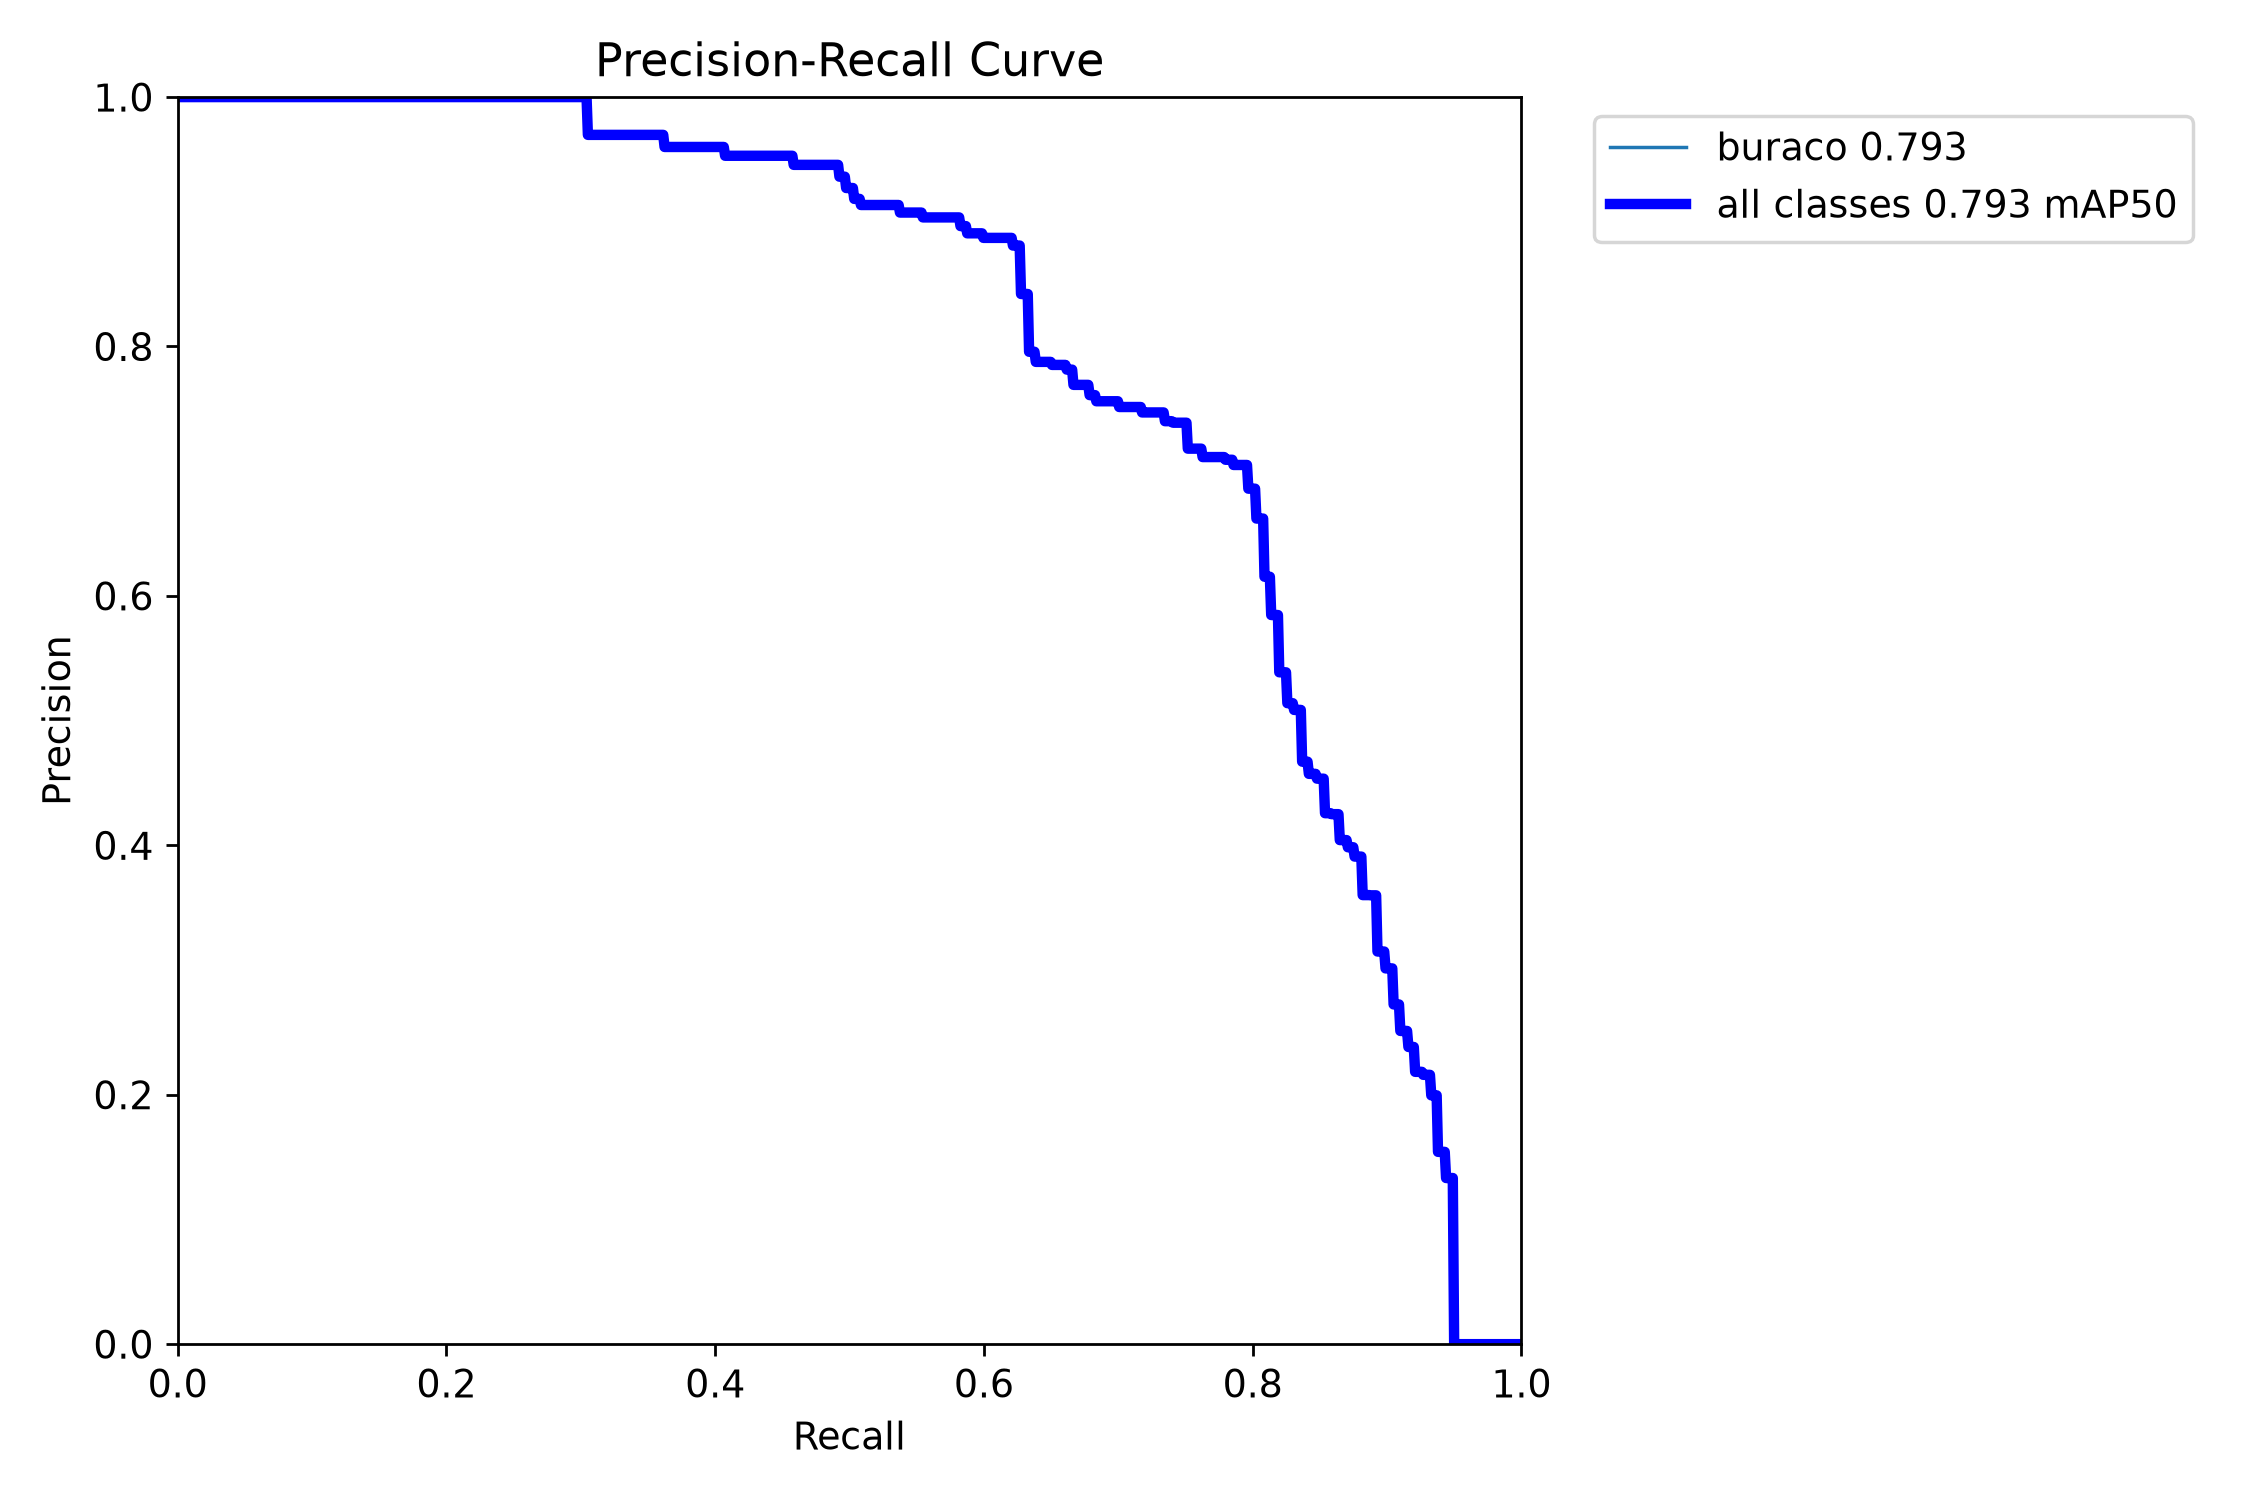

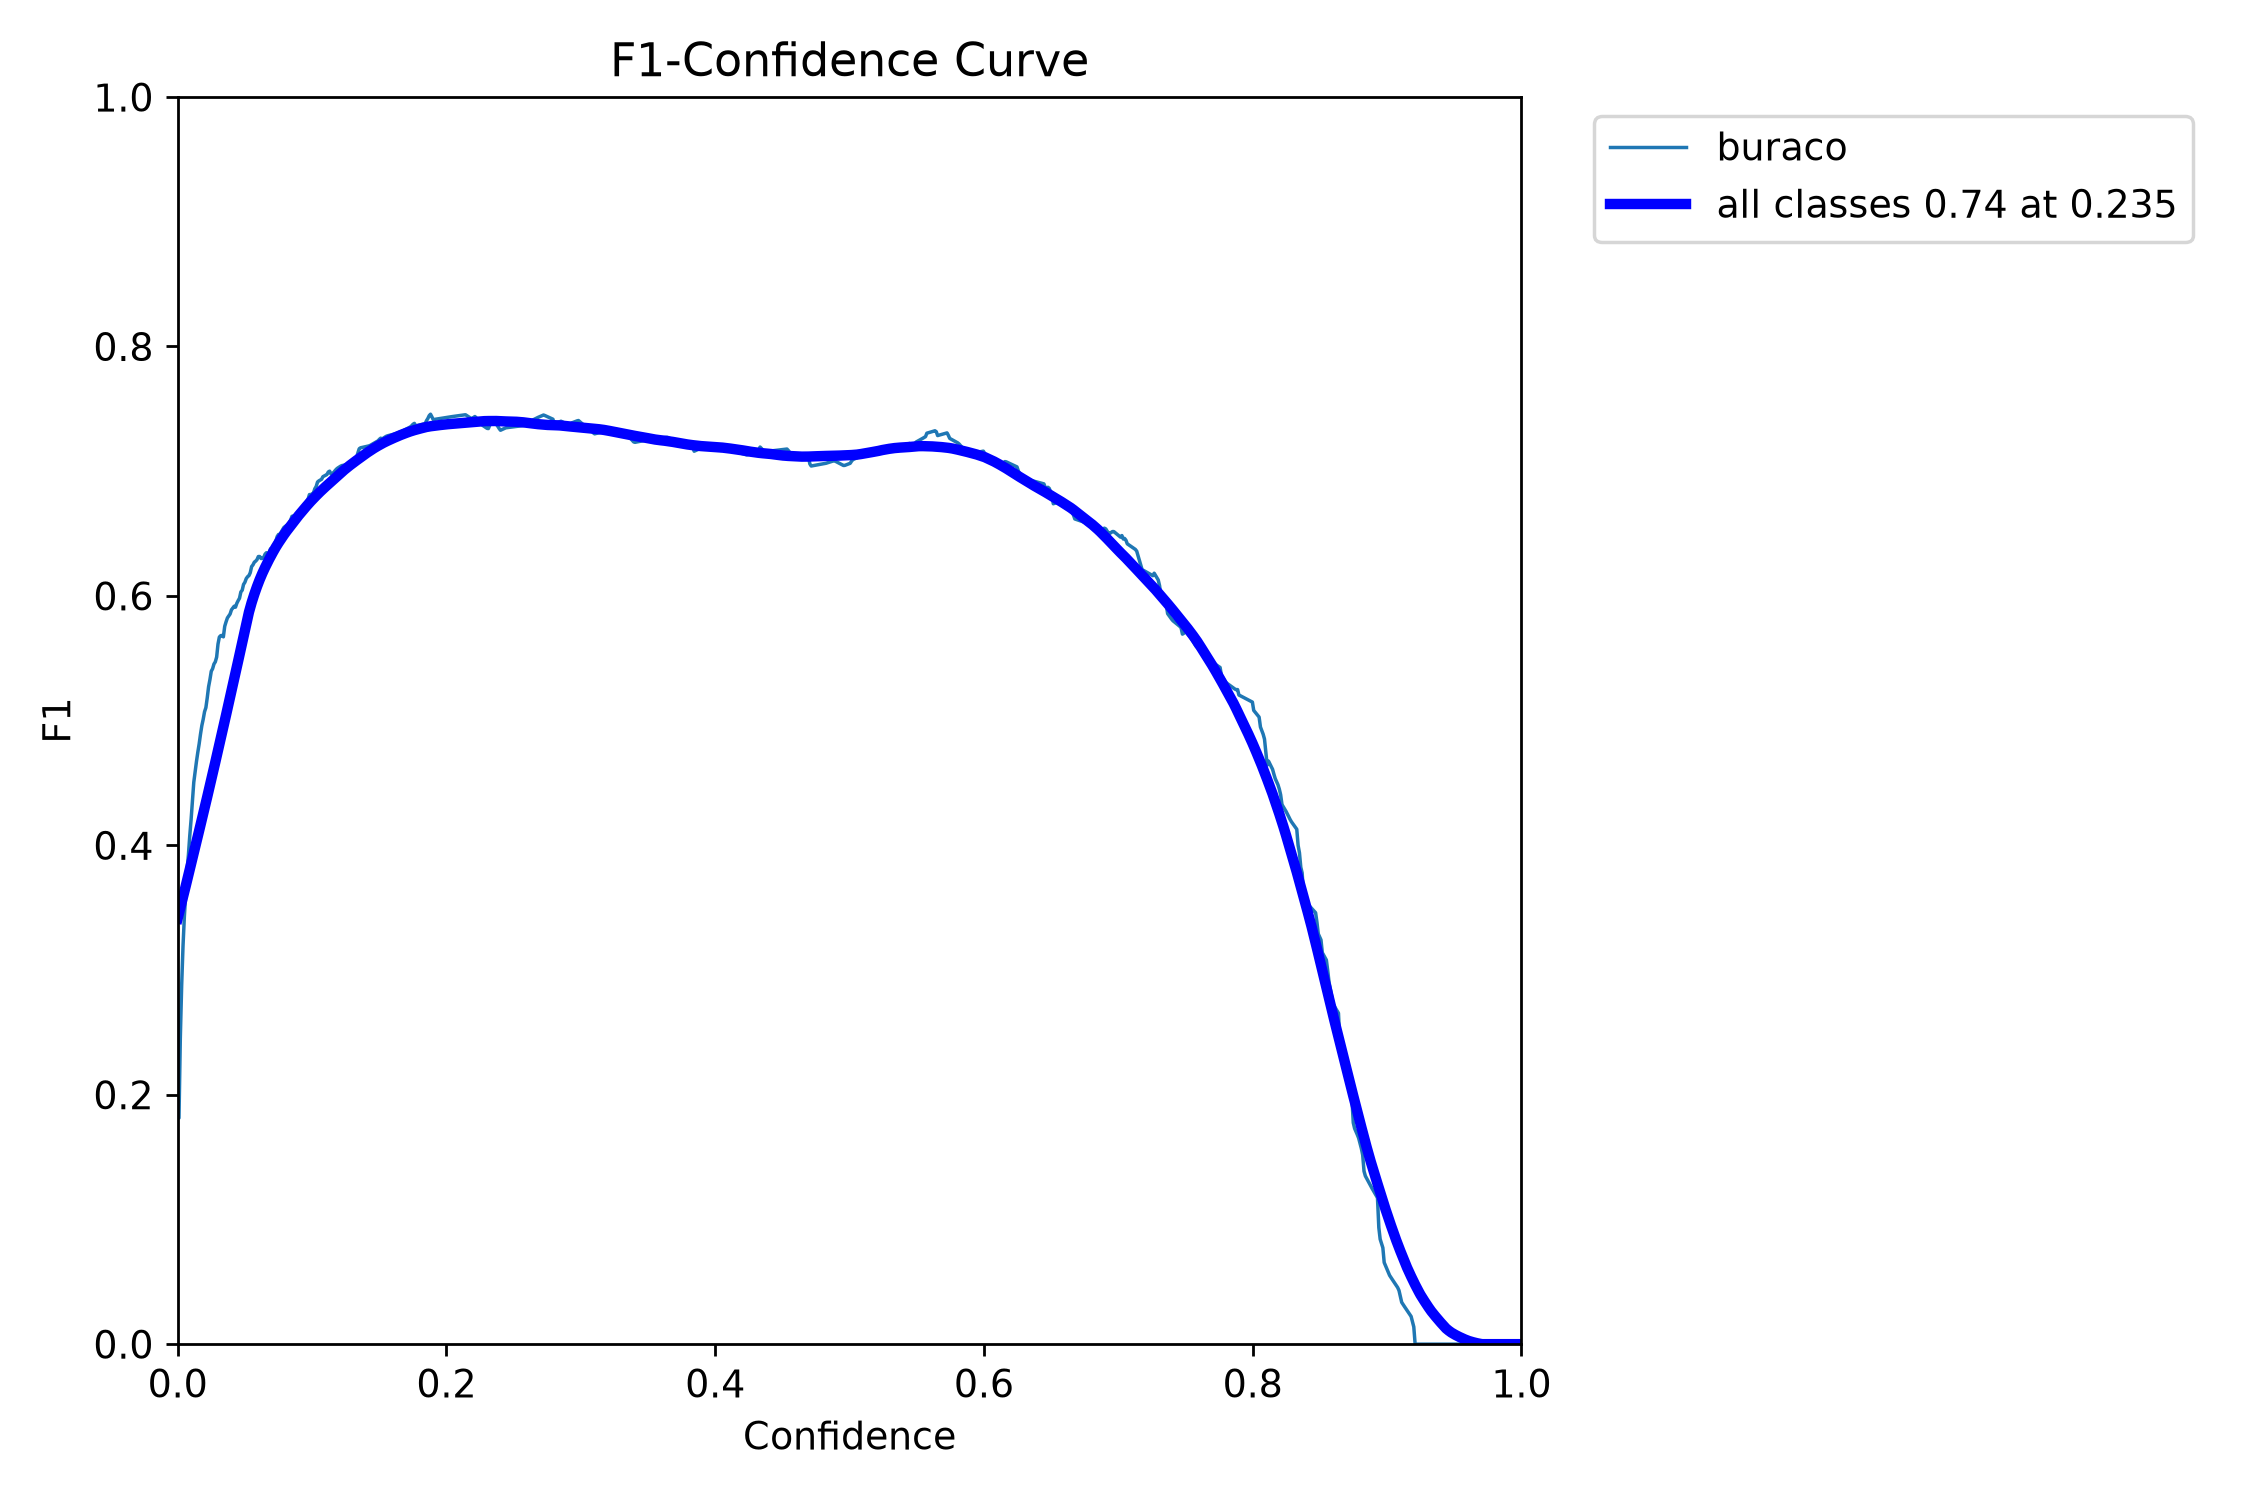

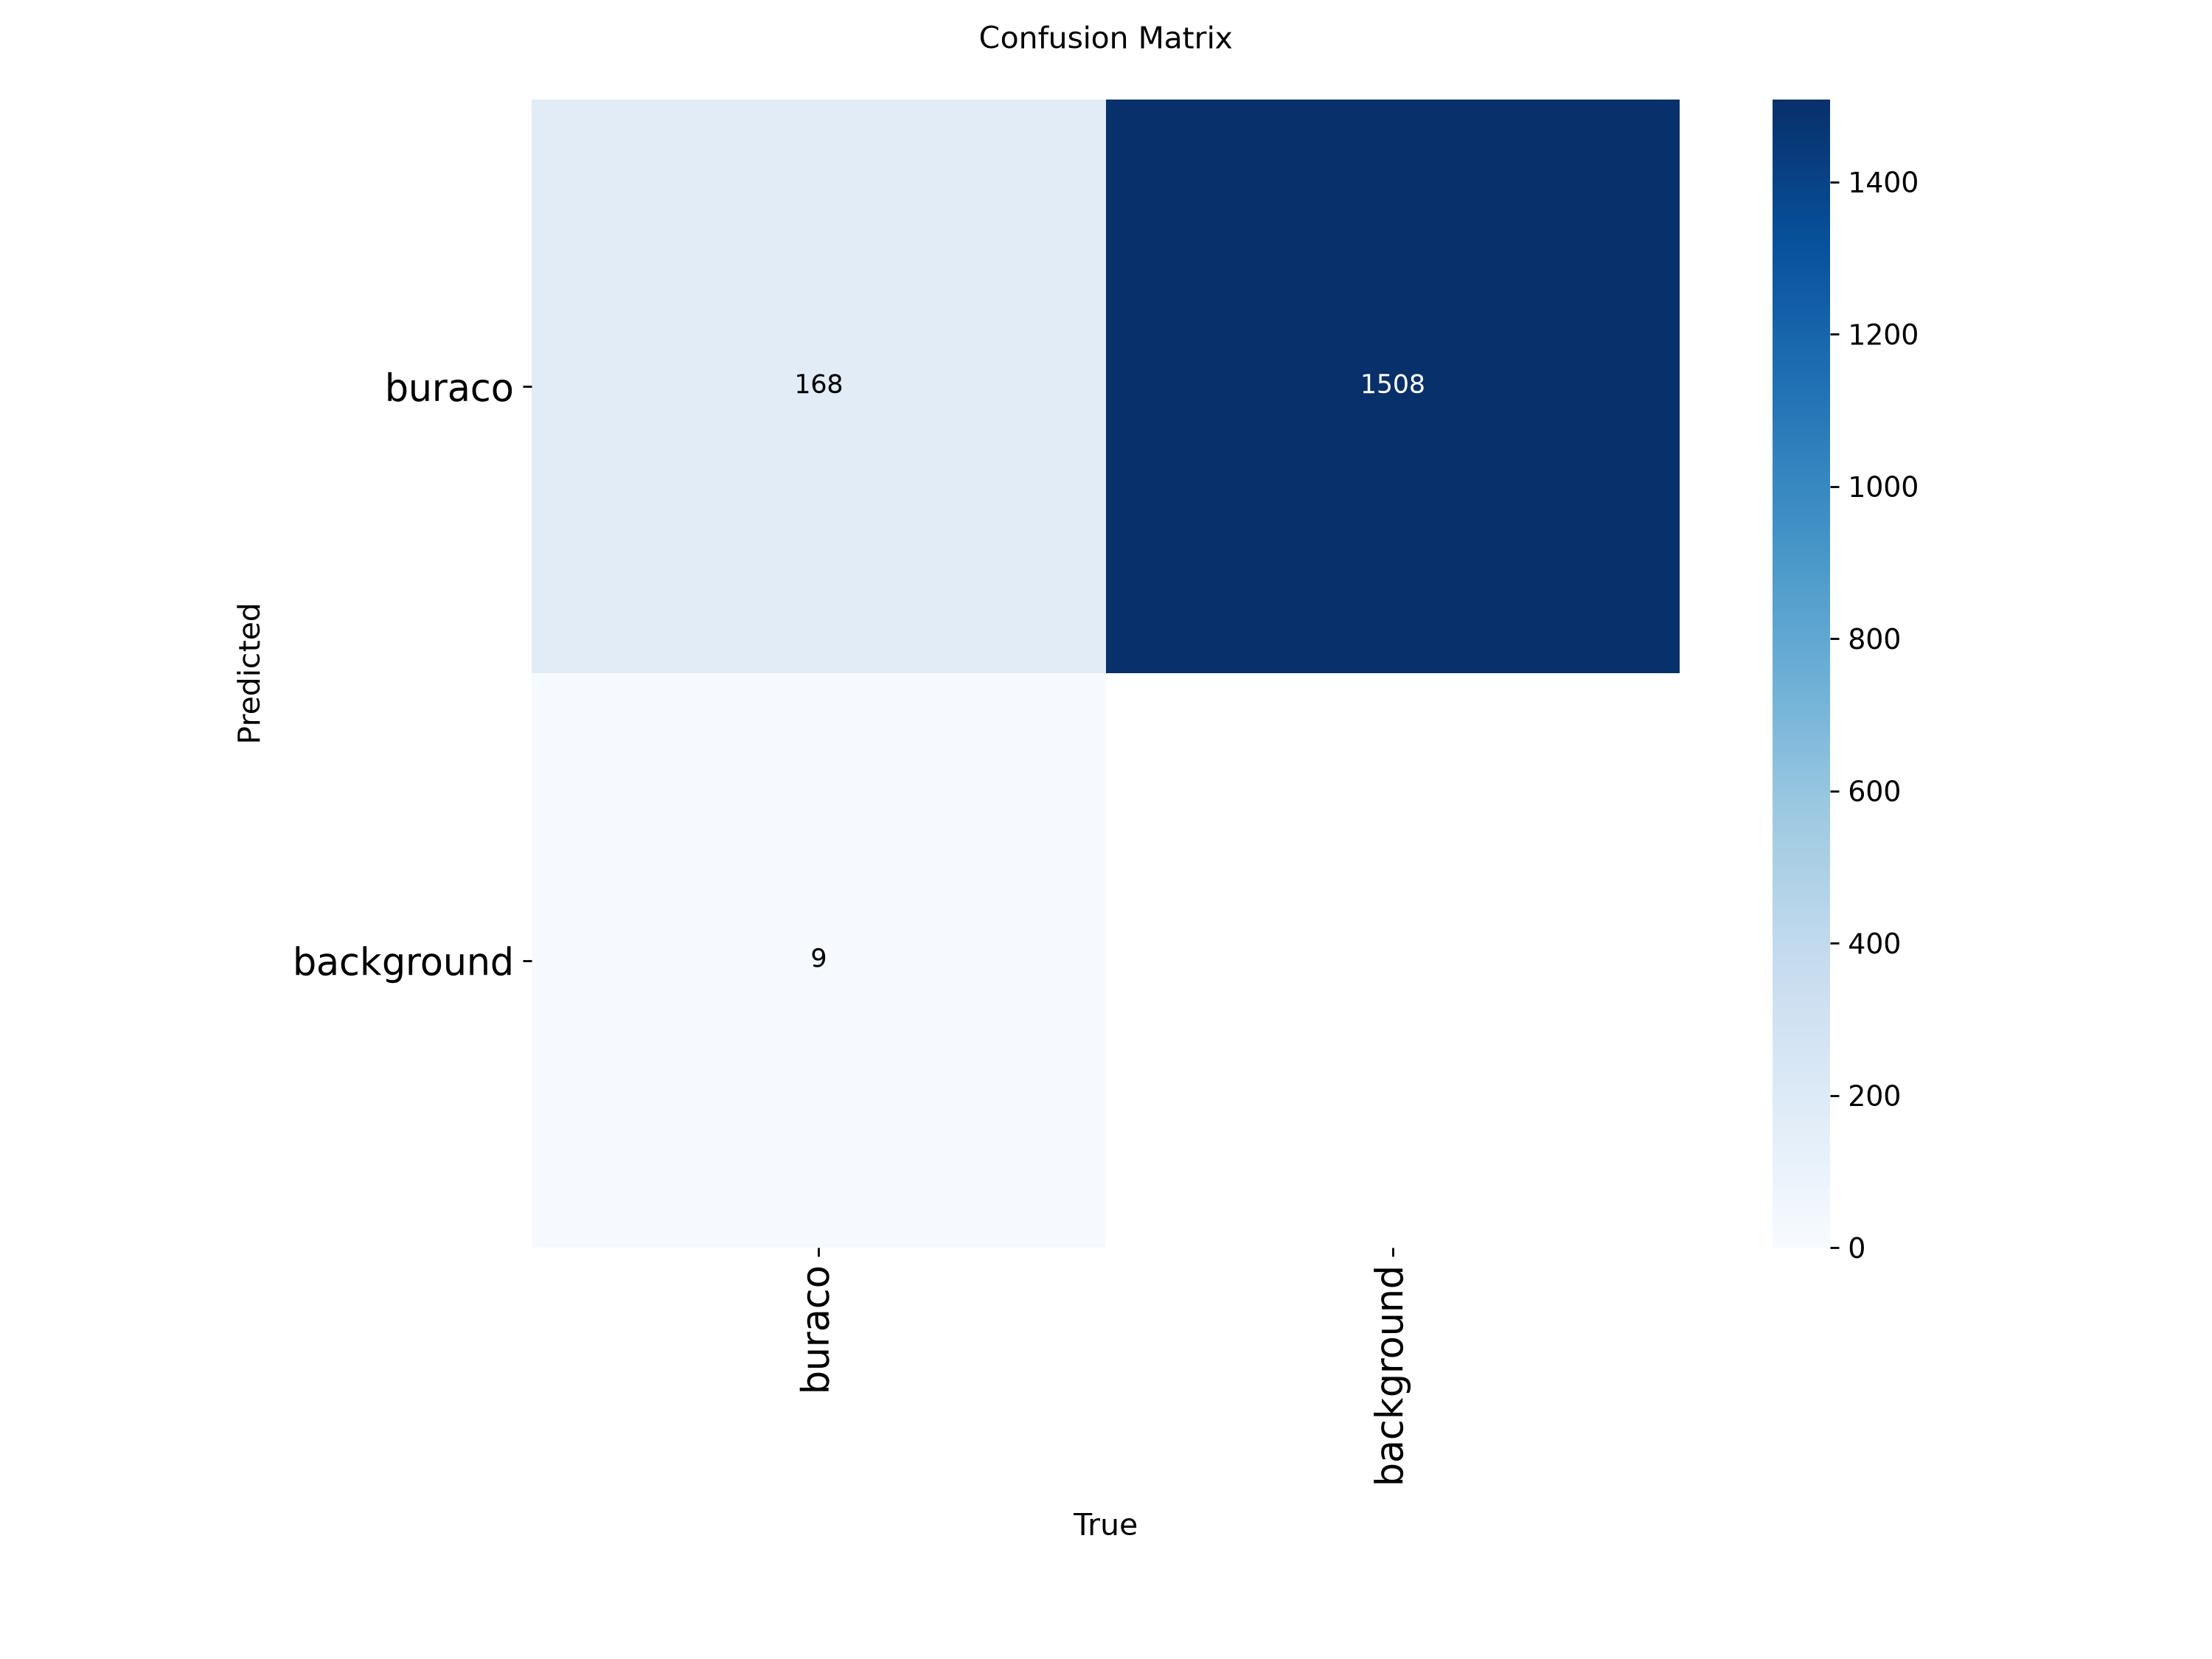

In [2]:
from IPython.display import Image, display
from pathlib import Path
pasta = Path("../resultados/val_teste")
for nomes in [("BoxPR_curve.png", "PR_curve.png"), ("BoxF1_curve.png", "F1_curve.png"), ("confusion_matrix.png",)]:
    # o Ultralytics 8.4 prefixa as curvas com "Box"; versões anteriores não
    p = next((pasta / f for f in nomes if (pasta / f).exists()), None)
    if p:
        display(Image(str(p), width=600))

## Acertos (vermelho = previsão, verde = gabarito)

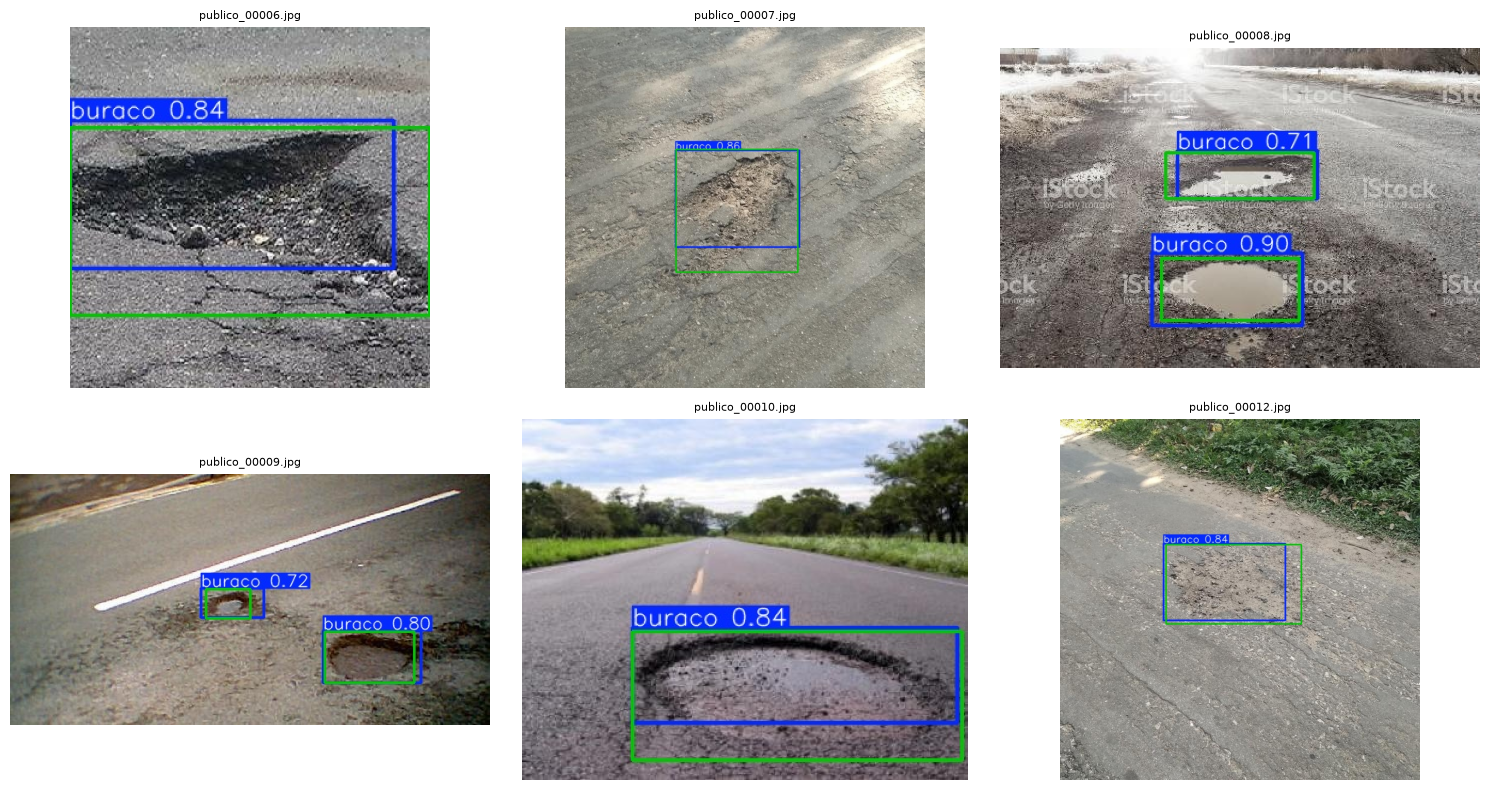

In [3]:
import matplotlib.pyplot as plt, cv2
ex = sorted(Path("../resultados/exemplos").glob("*.jpg"))[:6]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axs.ravel(), ex):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); ax.set_title(p.name, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## Erros (falsos positivos e falsos negativos)
Use estas imagens para a discussão de limitações no relatório (ex.: sombra confundida com buraco, buraco cheio de
água, foto noturna, ângulo rasante).

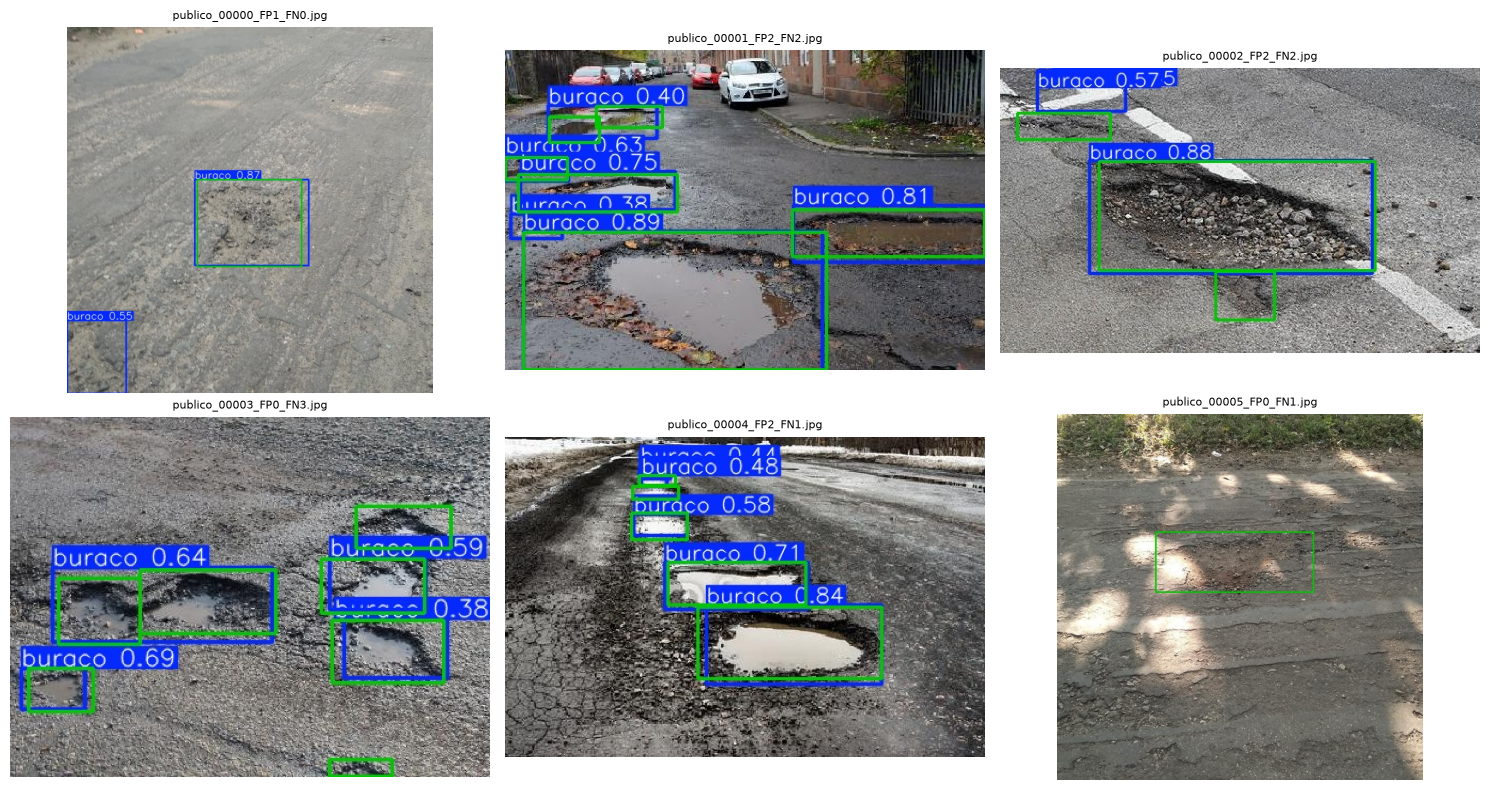

In [4]:
er = sorted(Path("../resultados/erros").glob("*.jpg"))[:6]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axs.ravel(), er):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); ax.set_title(p.name, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()